Đang huấn luyện mô hình SVM (RBF)...
-> Hoàn thành SVM trong: 1788.23 giây

Đang huấn luyện mô hình Random Forest...
-> Hoàn thành RF trong: 121.03 giây

Số lượng tham số (ước lượng) của SVM: 1,035,568
Số lượng tham số (ước lượng) của Random Forest: 140,572,728

Kết quả Accuracy và Macro-F1 trên tập TEST phân rã theo SNR:
-----------------------------------------------------------------
SNR: -10 dB | SVM Acc: 0.1531, F1: 0.1479 | RF Acc: 0.1490, F1: 0.1471
SNR:  -8 dB | SVM Acc: 0.1750, F1: 0.1638 | RF Acc: 0.1802, F1: 0.1736
SNR:  -6 dB | SVM Acc: 0.2062, F1: 0.1977 | RF Acc: 0.1750, F1: 0.1725
SNR:  -4 dB | SVM Acc: 0.2385, F1: 0.2291 | RF Acc: 0.2198, F1: 0.2117
SNR:  -2 dB | SVM Acc: 0.2594, F1: 0.2457 | RF Acc: 0.2646, F1: 0.2532
SNR:   0 dB | SVM Acc: 0.2844, F1: 0.2801 | RF Acc: 0.2760, F1: 0.2748
SNR:   2 dB | SVM Acc: 0.3125, F1: 0.3085 | RF Acc: 0.2885, F1: 0.2882
SNR:   4 dB | SVM Acc: 0.3604, F1: 0.3588 | RF Acc: 0.3448, F1: 0.3434
SNR:   6 dB | SVM Acc: 0.4115, F1: 0.4132 

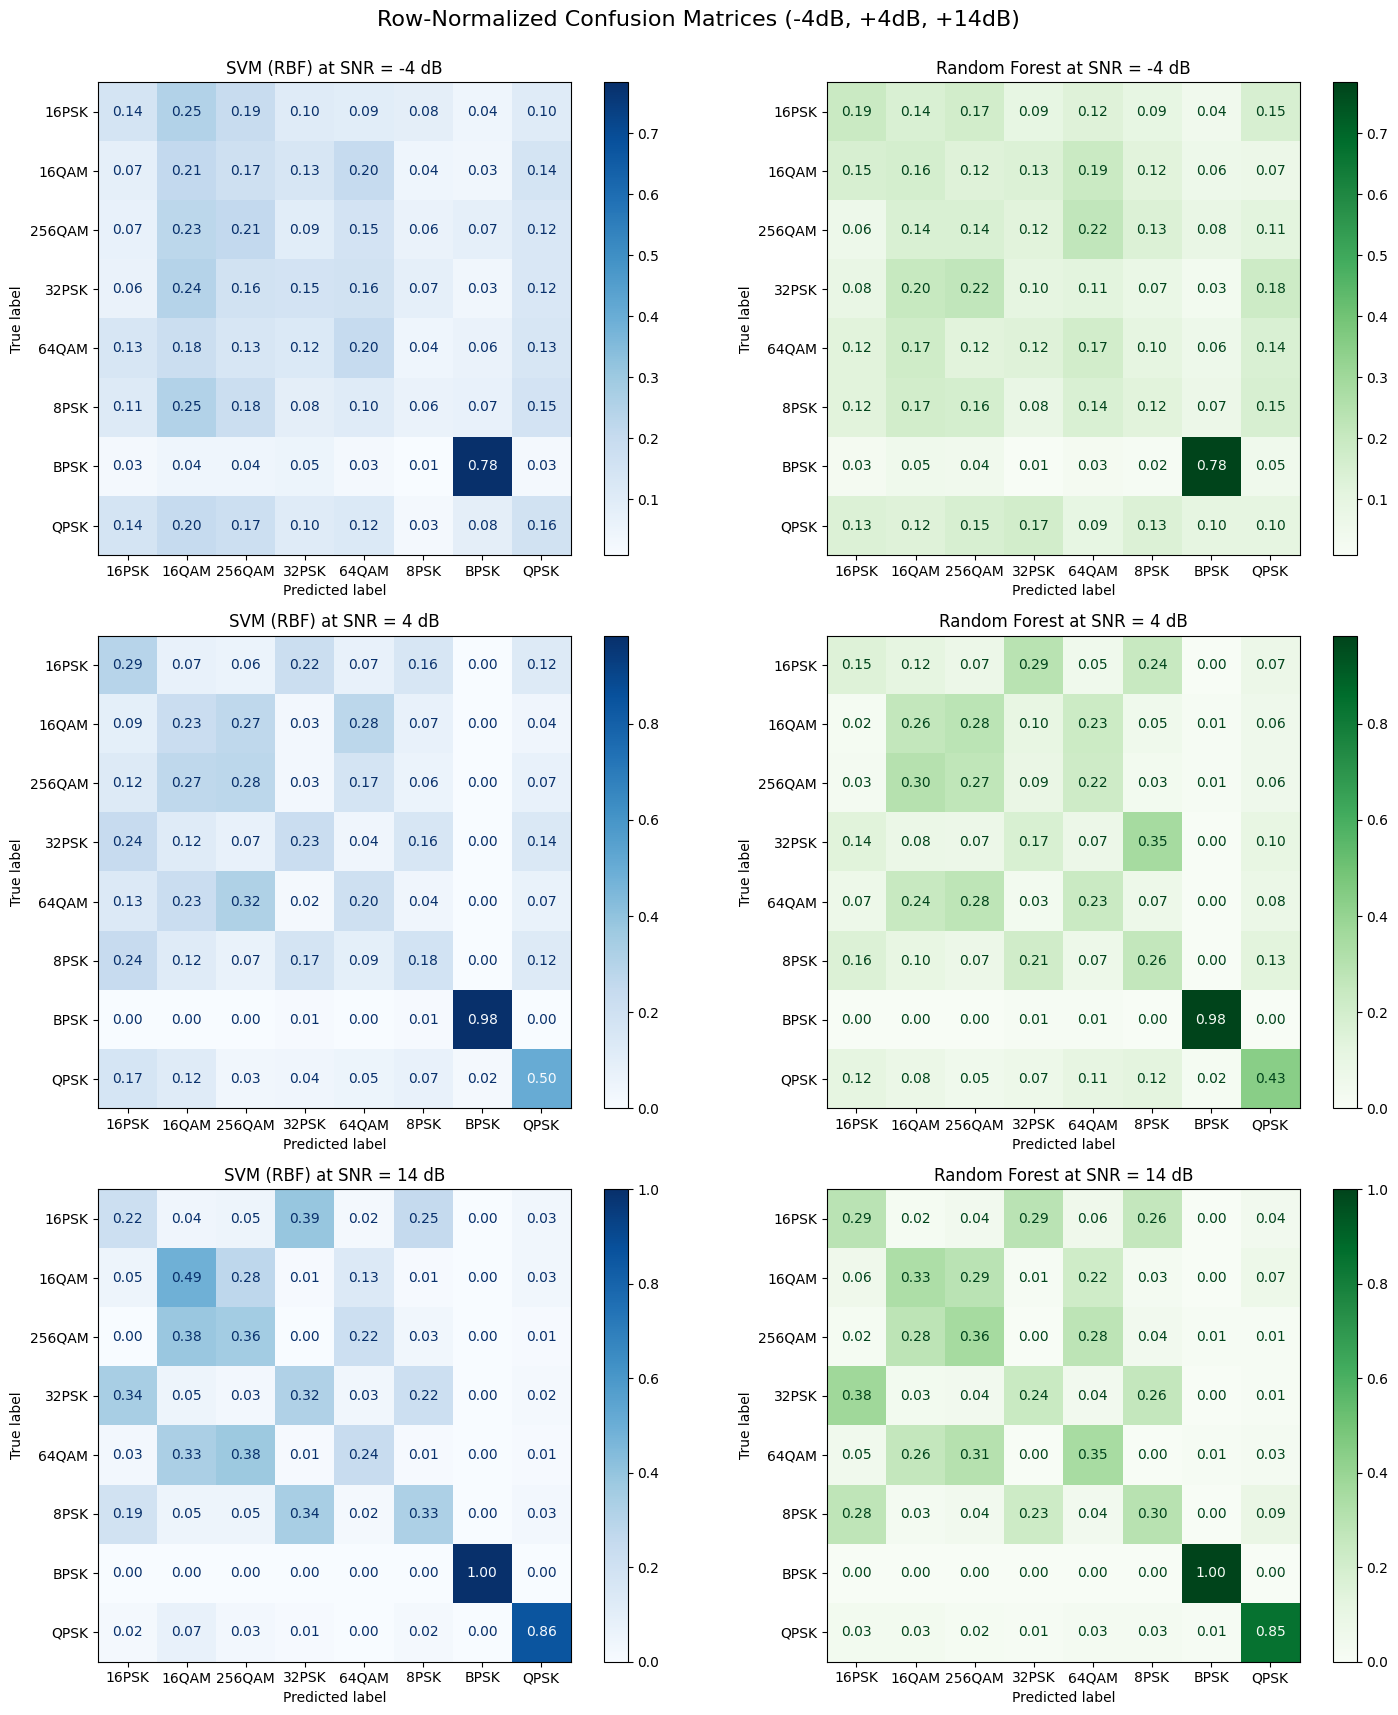

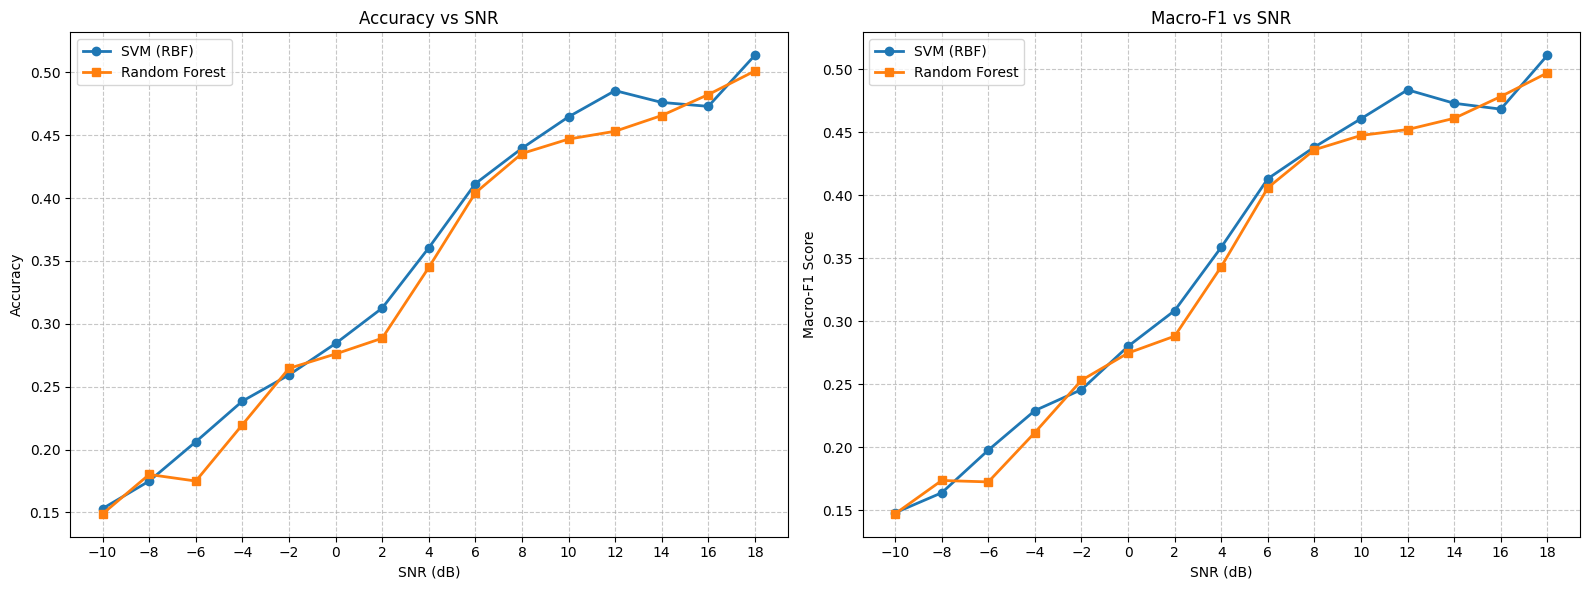

In [ ]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# ==========================================
# 1. TẢI DỮ LIỆU (Sử dụng đúng đường dẫn trong Colab)
# ==========================================
df_train = pd.read_csv('/content/features_train.csv')
df_val = pd.read_csv('/content/features_val.csv')
df_test = pd.read_csv('/content/features_test.csv')

feature_cols = [
    'C20', 'C21', 'C40', 'C41', 'C42', 'C60', 'C61', 'C62', 'C63',
    'sigma_aa', 'H_phase', 'sigma_ap', 'sigma_dp',
    'PAPR', 'gamma_max', 'Kurt_psd', 'Skew_psd', 'H_psd'
]
target_col = 'modulation'

X_train, y_train = df_train[feature_cols].values, df_train[target_col].values
X_test, y_test = df_test[feature_cols].values, df_test[target_col].values

# ==========================================
# 2. TIỀN XỬ LÝ (Zero Data Leakage)
# ==========================================
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
classes = le.classes_

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# 3. HUẤN LUYỆN MÔ HÌNH KINH ĐIỂN
# ==========================================
print("Đang huấn luyện mô hình SVM (RBF)...")
svm_model = SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)
start_time = time.time()
svm_model.fit(X_train_scaled, y_train_enc)
print(f"-> Hoàn thành SVM trong: {time.time() - start_time:.2f} giây")

print("\nĐang huấn luyện mô hình Random Forest...")
rf_model = RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)
start_time = time.time()
rf_model.fit(X_train_scaled, y_train_enc)
print(f"-> Hoàn thành RF trong: {time.time() - start_time:.2f} giây\n")

# Tính số lượng tham số ước lượng
svm_param_count = svm_model.support_.shape[0] * X_train_scaled.shape[1] + svm_model.intercept_.shape[0]
rf_param_count = sum([tree.tree_.node_count for tree in rf_model.estimators_]) * len(feature_cols)

print(f"Số lượng tham số (ước lượng) của SVM: {svm_param_count:,}")
print(f"Số lượng tham số (ước lượng) của Random Forest: {rf_param_count:,}\n")

# ==========================================
# 4. ĐÁNH GIÁ ACCURACY VÀ MACRO-F1 THEO TỪNG MỨC SNR
# ==========================================
snr_list = np.unique(df_test['snr_db'])
svm_acc_list, rf_acc_list = [], []
svm_f1_list, rf_f1_list = [], []

target_cm_snrs = [-4, 4, 14]
cm_results = {'SVM': {}, 'RF': {}}

print("Kết quả Accuracy và Macro-F1 trên tập TEST phân rã theo SNR:")
print("-" * 65)
for snr in snr_list:
    idx = (df_test['snr_db'] == snr).values
    X_test_snr = X_test_scaled[idx]
    y_test_snr = y_test_enc[idx]

    svm_preds = svm_model.predict(X_test_snr)
    rf_preds = rf_model.predict(X_test_snr)

    svm_acc = accuracy_score(y_test_snr, svm_preds)
    rf_acc = accuracy_score(y_test_snr, rf_preds)

    svm_f1 = f1_score(y_test_snr, svm_preds, average='macro')
    rf_f1 = f1_score(y_test_snr, rf_preds, average='macro')

    svm_acc_list.append(svm_acc)
    rf_acc_list.append(rf_acc)
    svm_f1_list.append(svm_f1)
    rf_f1_list.append(rf_f1)

    print(f"SNR: {snr:3d} dB | SVM Acc: {svm_acc:.4f}, F1: {svm_f1:.4f} | RF Acc: {rf_acc:.4f}, F1: {rf_f1:.4f}")

    if snr in target_cm_snrs:
        cm_results['SVM'][snr] = confusion_matrix(y_test_snr, svm_preds, normalize='true')
        cm_results['RF'][snr] = confusion_matrix(y_test_snr, rf_preds, normalize='true')

# ==========================================
# 5. VẼ MA TRẬN NHẦM LẪN VÀ BIỂU ĐỒ SO SÁNH
# ==========================================
# Vẽ Confusion Matrices
fig_cm, axes_cm = plt.subplots(3, 2, figsize=(15, 18))
fig_cm.suptitle('Row-Normalized Confusion Matrices (-4dB, +4dB, +14dB)', fontsize=16)

for i, snr in enumerate(target_cm_snrs):
    disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_results['SVM'][snr], display_labels=classes)
    disp_svm.plot(ax=axes_cm[i, 0], cmap='Blues', values_format='.2f')
    axes_cm[i, 0].set_title(f'SVM (RBF) at SNR = {snr} dB')

    disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_results['RF'][snr], display_labels=classes)
    disp_rf.plot(ax=axes_cm[i, 1], cmap='Greens', values_format='.2f')
    axes_cm[i, 1].set_title(f'Random Forest at SNR = {snr} dB')

plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

# Vẽ biểu đồ Accuracy & Macro-F1 vs SNR
fig_metrics, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(snr_list, svm_acc_list, marker='o', linewidth=2, label='SVM (RBF)')
ax1.plot(snr_list, rf_acc_list, marker='s', linewidth=2, label='Random Forest')
ax1.set_title('Accuracy vs SNR')
ax1.set_xlabel('SNR (dB)')
ax1.set_ylabel('Accuracy')
ax1.set_xticks(snr_list)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()

ax2.plot(snr_list, svm_f1_list, marker='o', linewidth=2, color='tab:blue', label='SVM (RBF)')
ax2.plot(snr_list, rf_f1_list, marker='s', linewidth=2, color='tab:orange', label='Random Forest')
ax2.set_title('Macro-F1 vs SNR')
ax2.set_xlabel('SNR (dB)')
ax2.set_ylabel('Macro-F1 Score')
ax2.set_xticks(snr_list)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
import joblib

# 1. Lưu 2 mô hình học máy
joblib.dump(svm_model, 'svm_model.pkl')
joblib.dump(rf_model, 'rf_model.pkl')

# 2. Lưu bộ tiền xử lý (Bắt buộc phải có để Dashboard nạp dữ liệu không bị sai lệch)
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("Đã lưu thành công 4 file .pkl vào thư mục hiện tại!")

Đã lưu thành công 4 file .pkl vào thư mục hiện tại!
